# 03 · Benefit — What do residents get, and where is the mismatch?

**NC3 · Lansing Economic Ecosystem and Community Wealth Analysis** — analysis notebook (run in order: 01 → 02 → 03)

| Notebook | Question |
|---|---|
| 01 Footprint | How big is each Big 4 institution? |
| 02 Retention | How much of its activity stays in the region? → *jobs are in the cities, most workers live elsewhere* |
| **03 Benefit** (this one) | **What do the residents of these places actually have — and where do job centers and resident hardship overlap?** (RQ3) |

### Indicators

| ID | Indicator | Source |
|---|---|---|
| C1 | Median household income | ACS B19013 |
| C2 | Poverty rate | ACS B17001 |
| C3 | Homeownership and median home value (main household-wealth proxies) | ACS B25003, B25077 |
| C4 | Households with interest, dividend or rental income (asset income) | ACS B19054 |
| C5 | Median household income by race/ethnicity of householder | ACS B19013B, H, I |
| C6 | Job-center / resident-hardship mismatch by census tract | LODES 2021 jobs + ACS 2020–2024 tracts |
| C6b | Resident conditions around each Big 4 site | ACS tracts within 2 km of each site |

### Rules used throughout
- **Current period** = ACS 2020–2024 5-year. **Change** compares it with 2015–2019 — two periods that do not overlap, as Census requires. 2015–2019 dollars are converted to 2024 dollars with CPI-U.
- **Every difference is tested** against ACS margins of error at the 90% level before it is called a difference.
- **Region** = Clinton, Eaton, Ingham. The 2015–2019 "MSA" row also includes Shiawassee County (older OMB definition), so it is **not** used for change.
- **Student-dominated tracts** (more than 40% of residents enrolled in college) are flagged: low student incomes are not the kind of hardship this analysis is about.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nc3_helpers import *

pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:,.2f}")
OUT_DIR = Path.cwd() / "outputs"; OUT_DIR.mkdir(exist_ok=True)

tracts = load_acs_tracts()
places = load_acs_places()
od = load_lodes_od()
cent = tract_centroids()
CPI = {2019: 255.657, 2024: 313.689}   # BLS CPI-U, U.S. city average, annual average (series CUUR0000SA0)
TO_2024 = CPI[2024] / CPI[2019]
print(f"Tracts: {len(tracts)} | places rows: {len(places)} | 2019$ -> 2024$ factor: {TO_2024:.3f}")

Tracts: 136 | places rows: 14 | 2019$ -> 2024$ factor: 1.227


## 1. Data checks

In [2]:
county_pop = places[(places.geo_level == "county") & (places.acs_period == "2020-2024")].set_index("NAME").population
check = tracts.groupby("county_name").population.sum().to_frame("sum of tracts")
check["county total"] = [county_pop[f"{c} County, Michigan"] for c in check.index]
check["difference"] = check["sum of tracts"] - check["county total"]

tracts["small_pop"] = tracts.population < 200
tracts["student_tract"] = tracts.student_share > 40
msa = places[places.geo_level == "msa"].set_index("acs_period").population
print("MSA population by period (definition change):", msa.to_dict())
print(f"Tracts with < 200 residents (excluded): {tracts.small_pop.sum()} | student-dominated tracts (>40% in college): {tracts.student_tract.sum()}")
print("Missing tract medians — income:", tracts.median_hh_income.isna().sum(), "| home value:", tracts.median_home_value.isna().sum())
check

MSA population by period (definition change): {'2015-2019': 546772, '2020-2024': 472669}
Tracts with < 200 residents (excluded): 4 | student-dominated tracts (>40% in college): 13
Missing tract medians — income: 8 | home value: 11


,sum of tracts,county total,difference
county_name,,,
Clinton,"79,626",79626,0.00
Eaton,"109,130",109130,0.00
Ingham,"283,913",283913,0.00


**Reading the checks.** Tract populations add up exactly to county totals. The MSA population falls from about 547,000 to 473,000 between periods only because Shiawassee County left the MSA definition. Missing tract medians are suppressed by Census in very small or student tracts — expected.

## 2. C1–C5 — Resident conditions by place, 2020–2024

In [3]:
cur = places[places.acs_period == "2020-2024"].copy()
label = {"Lansing city, Michigan": "Lansing (city)", "East Lansing city, Michigan": "East Lansing (city)",
         "Ingham County, Michigan": "Ingham County", "Eaton County, Michigan": "Eaton County",
         "Clinton County, Michigan": "Clinton County", "Lansing-East Lansing, MI Metro Area": "Region (3 counties)",
         "Michigan": "Michigan"}
cur["place"] = cur.NAME.map(label)
cur = cur.set_index("place").loc[list(label.values())]

c15 = pd.DataFrame(index=cur.index)
c15["median HH income ($)"] = cur.median_hh_income
c15["± MOE"] = cur.median_hh_income_moe
c15["poverty rate %"] = cur.below_poverty / cur.poverty_universe * 100
c15["poverty ± MOE (pp)"] = proportion_moe(cur.below_poverty, cur.below_poverty_moe, cur.poverty_universe, cur.poverty_universe_moe)
c15["homeownership %"] = cur.owner_occupied / cur.occupied_units * 100
c15["median home value ($)"] = cur.median_home_value
c15["asset-income households %"] = cur.hh_with_asset_income / cur.households_c19054 * 100
c15["unemployment %"] = cur.unemployed / cur.civilian_labor_force * 100
c15["college students % of pop"] = (cur.enrolled_undergrad + cur.enrolled_grad) / cur.population * 100
c15["Black / White NH income ratio"] = cur.median_hh_income_black / cur.median_hh_income_white_nh
c15["Hispanic / White NH income ratio"] = cur.median_hh_income_hispanic / cur.median_hh_income_white_nh
c15.to_csv(OUT_DIR / "benefit_v0_places_2020_2024.csv")
c15

,median HH income ($),± MOE,poverty rate %,poverty ± MOE (pp),homeownership %,median home value ($),asset-income households %,unemployment %,college students % of pop,Black / White NH income ratio,Hispanic / White NH income ratio
place,,,,,,,,,,,
Lansing (city),54382,1938,20.14,1.63,53.83,128700,12.71,8.23,8.02,0.77,0.97
East Lansing (city),45687,3696,33.02,2.74,38.55,270800,20.12,6.58,59.53,0.85,0.82
Ingham County,65526,1674,16.69,0.93,59.46,198800,17.70,6.24,16.50,0.60,0.81
Eaton County,79597,2067,8.33,0.69,74.17,216900,19.47,4.53,4.73,0.63,0.89
Clinton County,88210,4115,9.68,1.10,82.19,259500,22.74,3.83,6.38,0.97,1.02
Region (3 counties),72550,1364,13.49,0.60,66.61,216700,18.94,5.45,12.08,0.60,0.79
Michigan,72875,293,13.21,0.17,73.21,231600,18.42,5.70,6.07,0.58,0.86


### Change since 2015–2019 (inflation-adjusted, tested for significance)

The MSA row is left out (definition changed). A change is marked significant only if it clears the 90% margin of error.

In [4]:
old = places[places.acs_period == "2015-2019"].copy()
old["place"] = old.NAME.map(label); old = old.set_index("place")
geos = [g for g in label.values() if g != "Region (3 counties)"]
o, n = old.loc[geos], cur.loc[geos]

chg = pd.DataFrame(index=geos)
chg["income 2015-19 (2024$)"] = o.median_hh_income * TO_2024
chg["income 2020-24"] = n.median_hh_income
chg["real change %"] = (chg["income 2020-24"] / chg["income 2015-19 (2024$)"] - 1) * 100
chg["income change significant"] = diff_significant(o.median_hh_income * TO_2024, o.median_hh_income_moe * TO_2024,
                                                    n.median_hh_income, n.median_hh_income_moe)
pov_o = o.below_poverty / o.poverty_universe * 100; pov_n = n.below_poverty / n.poverty_universe * 100
pov_o_m = proportion_moe(o.below_poverty, o.below_poverty_moe, o.poverty_universe, o.poverty_universe_moe)
pov_n_m = proportion_moe(n.below_poverty, n.below_poverty_moe, n.poverty_universe, n.poverty_universe_moe)
chg["poverty 2015-19 %"] = pov_o; chg["poverty 2020-24 %"] = pov_n
chg["poverty change (pp)"] = pov_n - pov_o
chg["poverty change significant"] = diff_significant(pov_o, pov_o_m, pov_n, pov_n_m)
chg["home value real change %"] = (n.median_home_value / (o.median_home_value * TO_2024) - 1) * 100
chg["homeownership change (pp)"] = n.owner_occupied / n.occupied_units * 100 - o.owner_occupied / o.occupied_units * 100
chg.to_csv(OUT_DIR / "benefit_v0_change_2019_2024.csv")
chg

,income 2015-19 (2024$),income 2020-24,real change %,income change significant,poverty 2015-19 %,poverty 2020-24 %,poverty change (pp),poverty change significant,home value real change %,homeownership change (pp)
Lansing (city),"51,134",54382,6.35,True,24.63,20.14,-4.49,True,25.62,3.19
East Lansing (city),"48,916",45687,-6.60,False,40.98,33.02,-7.95,True,14.47,2.98
Ingham County,"64,874",65526,1.01,False,19.62,16.69,-2.93,True,19.49,0.99
Eaton County,"78,954",79597,0.81,False,10.15,8.33,-1.82,True,14.05,1.89
Clinton County,"86,368",88210,2.13,False,8.82,9.68,0.87,False,22.39,2.20
Michigan,"70,115",72875,3.94,True,14.36,13.21,-1.15,True,21.86,1.98


## 3. C6 — Where do job centers and resident hardship overlap?

For every tract: **jobs located in the tract per 100 residents** (LODES 2021, the two flagged administrative blocks excluded) against the **poverty rate of the people who live there** (ACS 2020–2024).

| Quadrant | Jobs per 100 residents | Poverty rate | Meaning |
|---|---|---|---|
| **Mismatch** | ≥ 100 (more jobs than residents) | above region | Economic activity is here; residents are poorer than the region |
| Prosperous job center | ≥ 100 | at or below region | Jobs and resident well-being line up |
| Struggling residential | < 100 | above region | Hardship without a local job base |
| Stable residential | < 100 | at or below region | Typical residential tract |

Thresholds are simple on purpose; section 6 tests stricter ones. Tracts with < 200 residents and student-dominated tracts are not classified.

In [5]:
anom = flag_anomalous_blocks(od)
jobs = od[~od.w_geocode.isin(anom)].groupby("w_tract11").S000.sum().rename("jobs_2021")
T = tracts.merge(jobs, left_on="geoid", right_index=True, how="left").merge(cent, on="geoid", how="left")
T["jobs_2021"] = T.jobs_2021.fillna(0)
T["jobs_per_100_res"] = T.jobs_2021 / T.population.where(T.population > 0) * 100

REGION_POV = T.below_poverty.sum() / T.poverty_universe.sum() * 100
def quadrant(r, job_cut=100, pov_cut=REGION_POV):
    if r.small_pop: return "Not classified: < 200 residents"
    if r.student_tract: return "Not classified: student-dominated"
    hi_job, hi_pov = r.jobs_per_100_res >= job_cut, r.poverty_rate > pov_cut
    return {(True, True): "Mismatch", (True, False): "Prosperous job center",
            (False, True): "Struggling residential", (False, False): "Stable residential"}[(hi_job, hi_pov)]
T["quadrant"] = T.apply(quadrant, axis=1)
print(f"Region poverty rate (pooled across tracts): {REGION_POV:.1f}%")
summary = T.groupby("quadrant").agg(tracts=("geoid", "size"), residents=("population", "sum"), jobs=("jobs_2021", "sum"),
                                    poverty_rate=("poverty_rate", "median"))
summary["share of residents %"] = summary.residents / T.population.sum() * 100
summary["share of jobs %"] = summary.jobs / T.jobs_2021.sum() * 100
summary

Region poverty rate (pooled across tracts): 13.5%


,tracts,residents,jobs,poverty_rate,share of residents %,share of jobs %
quadrant,,,,,,
Mismatch,6,"20,372","51,016",26.12,4.31,24.81
Not classified: < 200 residents,4,272,"1,751",26.97,0.06,0.85
Not classified: student-dominated,11,"31,870","20,192",56.96,6.74,9.82
Prosperous job center,4,"11,421","19,970",7.33,2.42,9.71
Stable residential,73,"281,770","67,478",6.89,59.61,32.81
Struggling residential,38,"126,964","45,254",19.89,26.86,22.00


In [6]:
mism = T[T.quadrant == "Mismatch"].sort_values("jobs_2021", ascending=False)
mism[["geoid", "NAME", "population", "jobs_2021", "jobs_per_100_res", "poverty_rate", "median_hh_income", "owner_rate"]]

,geoid,NAME,population,jobs_2021,jobs_per_100_res,poverty_rate,median_hh_income,owner_rate
129,26065006700,"Census Tract 67, Ingham, MI","4,248","19,413",457,19.14,"44,614",34.45
108,26065005304,"Census Tract 53.04, Ingham, MI","2,985","11,251",377,36.56,"39,861",33.81
127,26065006500,"Census Tract 65, Ingham, MI","3,487","9,252",265,16.99,"56,215",50.59
28,26045020202,"Census Tract 202.02, Eaton, MI","4,411","5,423",123,20.59,"59,604",65.08
128,26065006600,"Census Tract 66, Ingham, MI","3,284","3,631",111,31.66,"40,955",20.95
54,26065000600,"Census Tract 6, Ingham, MI","1,957","2,046",105,36.62,"40,119",18.57


## 4. C6b — Resident conditions around each Big 4 site

Tracts whose center lies within **2 km** of each site; **if fewer than 3 qualifying tracts are that close, the 3 nearest are used instead** and the distance is reported. This matters for MSU (every tract within 2 km is student-dominated, so the nearest permanent-resident neighborhoods are used) and for GM Delta Township (large suburban tracts whose centers are more than 2 km from the plant). Rates are pooled (total people in poverty ÷ total population counted); income is a population-weighted average of tract medians (an approximation — medians cannot be added exactly). Local government has no single site and is not shown. The Capitol complex and GM Grand River are about 1 km apart, so their neighborhoods overlap.

In [7]:
SITES = {
    "MSU campus":                (42.7164, -84.4850, "MSU"),
    "State Capitol complex":     (42.7337, -84.5555, "State Government"),
    "GM Lansing Grand River":    (42.7238, -84.5614, "GM"),
    "GM Lansing Delta Township": (42.6908, -84.6881, "GM"),
}
def neighborhood(lat, lon, km=2.0, min_tracts=3, drop_students=True):
    base = T[~T.small_pop].assign(dist_km=km_between(lat, lon, T.lat, T.lon))
    if drop_students:
        base = base[~base.student_tract]
    sel = base[base.dist_km <= km]
    return sel if len(sel) >= min_tracts else base.nsmallest(min_tracts, "dist_km")

def describe(sel):
    pop = sel.population.sum()
    w = sel.dropna(subset=["median_hh_income"])
    return pd.Series({
        "tracts": len(sel), "residents": pop,
        "poverty rate %": sel.below_poverty.sum() / sel.poverty_universe.sum() * 100,
        "median income (pop-weighted) $": np.average(w.median_hh_income, weights=w.population) if len(w) else np.nan,
        "homeownership %": sel.owner_occupied.sum() / sel.occupied_units.sum() * 100,
        "asset-income households %": sel.hh_with_asset_income.sum() / sel.households_c19054.sum() * 100,
        "college students %": (sel.enrolled_undergrad.sum() + sel.enrolled_grad.sum()) / pop * 100 if pop else np.nan,
        "jobs in these tracts": sel.jobs_2021.sum(),
        "farthest tract center (km)": sel.dist_km.max() if "dist_km" in sel else np.nan})

nbhd = pd.DataFrame({site: describe(neighborhood(lat, lon)) for site, (lat, lon, _) in SITES.items()}).T
region = describe(T[~T.small_pop & ~T.student_tract]); region.name = "Region (non-student tracts)"
nbhd = pd.concat([nbhd, region.to_frame().T])
nbhd.to_csv(OUT_DIR / "benefit_v0_site_neighborhoods.csv", index_label="site")
nbhd

,tracts,residents,poverty rate %,median income (pop-weighted) $,homeownership %,asset-income households %,college students %,jobs in these tracts,farthest tract center (km)
MSU campus,3.00,"11,981",28.89,"55,039",52.16,21.15,29.35,"2,807",3.02
State Capitol complex,7.00,"20,860",24.41,"46,568",39.27,10.31,8.84,"28,639",1.97
GM Lansing Grand River,4.00,"14,917",17.30,"56,881",49.20,8.96,9.31,"24,045",1.54
GM Lansing Delta Township,3.00,"14,797",3.99,"87,521",74.62,20.30,6.72,"15,023",4.65
Region (non-student tracts),121,"440,527",11.98,"79,315",68.68,19.17,6.96,"183,718",NaN


### Chart — Poverty rate of residents living near each site

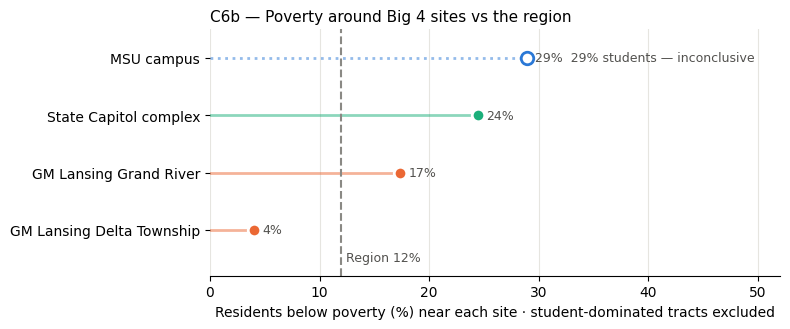

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
sites = list(SITES)
vals = nbhd.loc[sites, "poverty rate %"]
order = vals.sort_values().index
reg = nbhd.loc["Region (non-student tracts)", "poverty rate %"]
for i, s in enumerate(order):
    c = BIG4_COLORS[SITES[s][2]]
    inconclusive = nbhd.loc[s, "college students %"] > 20
    ax.plot([0, vals[s]], [i, i], color=c, lw=2, alpha=0.5, ls=":" if inconclusive else "-")
    ax.plot(vals[s], i, "o", ms=9, mew=2, mec=c if inconclusive else "white", color="white" if inconclusive else c)
    note = f"  {nbhd.loc[s, 'college students %']:.0f}% students — inconclusive" if inconclusive else ""
    ax.text(vals[s] + 0.8, i, f"{vals[s]:.0f}%{note}", va="center", fontsize=9, color="#52514e")
ax.axvline(reg, color=REGION_COLOR, ls="--", lw=1.5)
ax.text(reg + 0.4, -0.55, f"Region {reg:.0f}%", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)), order); ax.set_xlim(0, 52); ax.set_ylim(-0.8, len(order) - 0.5)
ax.set_xlabel("Residents below poverty (%) near each site · student-dominated tracts excluded")
for s_ in ["top", "right", "left"]: ax.spines[s_].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.set_title("C6b — Poverty around Big 4 sites vs the region", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

### Chart — Every tract: jobs located there vs poverty of residents
Grey = tract; hollow = student-dominated (not classified); colored = neighborhood of a Big 4 site (same rule as the table). Upper-right area = mismatch.

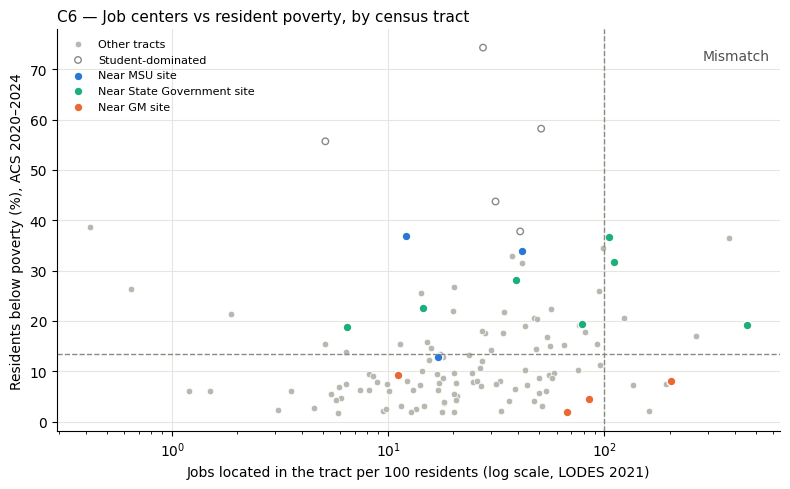

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
P = T[~T.small_pop & (T.jobs_per_100_res > 0)].copy()
P["near_site"] = ""
for s, (lat, lon, _) in SITES.items():   # same neighborhood rule as the table
    P.loc[P.geoid.isin(neighborhood(lat, lon).geoid) & (P.near_site == ""), "near_site"] = s
base = P[(P.near_site == "") & ~P.student_tract]
ax.scatter(base.jobs_per_100_res, base.poverty_rate, s=22, color="#b8b7b0", edgecolor="white", lw=0.5, label="Other tracts")
stu = P[P.student_tract]
ax.scatter(stu.jobs_per_100_res, stu.poverty_rate, s=22, facecolor="none", edgecolor="#8a8984", lw=1, label="Student-dominated")
for inst in ["MSU", "State Government", "GM"]:
    sel = P[(P.near_site != "") & P.near_site.map(lambda s: SITES[s][2] if s else "").eq(inst) & ~P.student_tract]
    if len(sel):
        ax.scatter(sel.jobs_per_100_res, sel.poverty_rate, s=40, color=BIG4_COLORS[inst], edgecolor="white", lw=1, label=f"Near {inst} site")
ax.axvline(100, color="#8a8984", ls="--", lw=1); ax.axhline(REGION_POV, color="#8a8984", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("Jobs located in the tract per 100 residents (log scale, LODES 2021)")
ax.set_ylabel("Residents below poverty (%), ACS 2020–2024")
ax.text(ax.get_xlim()[1] * 0.9, ax.get_ylim()[1] * 0.95, "Mismatch", ha="right", va="top", fontsize=10, color="#52514e")
for s_ in ["top", "right"]: ax.spines[s_].set_visible(False)
ax.grid(color="#e6e5e0", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("C6 — Job centers vs resident poverty, by census tract", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

## 5. Save outputs

In [10]:
T[["geoid", "NAME", "county_name", "population", "jobs_2021", "jobs_per_100_res", "poverty_rate", "median_hh_income",
   "owner_rate", "median_home_value", "asset_income_rate", "student_share", "quadrant", "lat", "lon"]].to_csv(
    OUT_DIR / "benefit_v0_tracts.csv", index=False)
print(*sorted(p.name for p in OUT_DIR.glob("benefit_*.csv")), sep="\n")

benefit_robustness.csv
benefit_v0_change_2019_2024.csv
benefit_v0_places_2020_2024.csv
benefit_v0_site_neighborhoods.csv
benefit_v0_tracts.csv


## 6. Robustness — which conclusions hold?

Place-level claims are tested against ACS margins of error (90%). Tract-level claims are tested by changing the analyst's choices: stricter thresholds, a smaller and larger radius, and including student tracts.

In [11]:
def verdict(a, b): return "Robust" if (a and b) else "Not supported"
R = []
L, G = cur.loc["Lansing (city)"], cur.loc["Region (3 counties)"]
sig = diff_significant(L.median_hh_income, L.median_hh_income_moe, G.median_hh_income, G.median_hh_income_moe)
R.append(("C1", "Lansing residents' median income is below the region's",
          f"${L.median_hh_income:,.0f} ± {L.median_hh_income_moe:,.0f}", f"${G.median_hh_income:,.0f} ± {G.median_hh_income_moe:,.0f}",
          verdict(L.median_hh_income < G.median_hh_income, sig)))
pl, pr = c15.loc["Lansing (city)", "poverty rate %"], c15.loc["Region (3 counties)", "poverty rate %"]
sig = diff_significant(pl, c15.loc["Lansing (city)", "poverty ± MOE (pp)"], pr, c15.loc["Region (3 counties)", "poverty ± MOE (pp)"])
R.append(("C2", "Lansing's poverty rate is above the region's", f"{pl:.1f}%", f"{pr:.1f}%", verdict(pl > pr, sig)))
rc = chg.loc["Lansing (city)"]
R.append(("C1", "Lansing's real median income rose between 2015-19 and 2020-24", f"{rc['real change %']:+.1f}%",
          "significant" if rc["income change significant"] else "not significant", verdict(rc["real change %"] > 0, rc["income change significant"])))
b, w = L.median_hh_income_black, L.median_hh_income_white_nh
sig = diff_significant(b, L.median_hh_income_black_moe, w, L.median_hh_income_white_nh_moe)
R.append(("C5", "In Lansing, Black households' median income is below White non-Hispanic households'",
          f"${b:,.0f} ± {L.median_hh_income_black_moe:,.0f}", f"${w:,.0f} ± {L.median_hh_income_white_nh_moe:,.0f}", verdict(b < w, sig)))
strict = T.apply(lambda r: quadrant(r, job_cut=150, pov_cut=REGION_POV + 5), axis=1)
n_base, n_strict = (T.quadrant == "Mismatch").sum(), (strict == "Mismatch").sum()
R.append(("C6", "Mismatch tracts exist (job centers whose residents are poorer than the region)",
          f"{n_base} tracts (≥100 jobs/100 res, > region)", f"{n_strict} tracts (≥150, > region + 5 pp)", verdict(n_base > 0, n_strict > 0)))
for site in ["State Capitol complex", "GM Lansing Grand River", "GM Lansing Delta Township", "MSU campus"]:
    lat, lon, _ = SITES[site]
    d_small = describe(neighborhood(lat, lon, 1.5, 3))
    p_small, stud = d_small["poverty rate %"], d_small["college students %"]
    p_large = describe(neighborhood(lat, lon, 3.0, 5))["poverty rate %"]
    p_stud = describe(neighborhood(lat, lon, 2.0, 3, drop_students=False))["poverty rate %"]
    reg_p = nbhd.loc["Region (non-student tracts)", "poverty rate %"]
    R.append(("C6b", f"Residents near {site} are poorer than the region ({reg_p:.0f}%)",
              f"small (1.5 km/3 tracts): {p_small:.0f}% | large (3 km/5 tracts): {p_large:.0f}%",
              f"with students: {p_stud:.0f}% | students in neighborhood: {stud:.0f}%",
              "Inconclusive: student population" if stud > 20 else verdict(p_small > reg_p and p_large > reg_p, True)))
robust = pd.DataFrame(R, columns=["indicator", "claim", "test_A", "test_B", "verdict"])
robust.to_csv(OUT_DIR / "benefit_robustness.csv", index=False)
robust

,indicator,claim,test_A,test_B,verdict
0,C1,Lansing residents' median income is below the ...,"$54,382 ± 1,938","$72,550 ± 1,364",Robust
1,C2,Lansing's poverty rate is above the region's,20.1%,13.5%,Robust
2,C1,Lansing's real median income rose between 2015...,+6.4%,significant,Robust
3,C5,"In Lansing, Black households' median income is...","$44,191 ± 4,793","$57,149 ± 2,119",Robust
4,C6,Mismatch tracts exist (job centers whose resid...,"6 tracts (≥100 jobs/100 res, > region)","2 tracts (≥150, > region + 5 pp)",Robust
5,C6b,Residents near State Capitol complex are poore...,small (1.5 km/3 tracts): 27% | large (3 km/5 t...,with students: 24% | students in neighborhood:...,Robust
6,C6b,Residents near GM Lansing Grand River are poor...,small (1.5 km/3 tracts): 14% | large (3 km/5 t...,with students: 17% | students in neighborhood: 9%,Robust
7,C6b,Residents near GM Lansing Delta Township are p...,small (1.5 km/3 tracts): 4% | large (3 km/5 tr...,with students: 4% | students in neighborhood: 7%,Not supported
8,C6b,Residents near MSU campus are poorer than the ...,small (1.5 km/3 tracts): 29% | large (3 km/5 t...,with students: 44% | students in neighborhood:...,Inconclusive: student population


### Reading the robustness table

- **Place-level gaps (C1, C2, C5) and the income gain in Lansing** clear the ACS margins of error — these are trustworthy.
- **Mismatch tracts** survive stricter thresholds (fewer of them, but they remain).
- **Capitol complex and GM Grand River neighborhoods** are poorer than the region whether a small or large neighborhood is drawn.
- **GM Delta Township** neighborhoods are *not* poorer — this is a real contrast, not a data failure.
- **MSU** is inconclusive because of the student population, even outside student-dominated tracts.

## 7. Findings (draft)

First-pass readings. Descriptive, not causal; every difference below cleared the 90% margin of error or a sensitivity test (section 6).

1. **The cities that host the Big 4 are poorer than the region they anchor.** Lansing's median household income is **$54,382** vs **$72,550** for the three-county region; its poverty rate is **20%** vs **13.5%**; homeownership **54%** vs **67%**; and only **13%** of Lansing households have any interest, dividend or rental income (region **19%**). Home values — the main source of household wealth — are about **$129K** in Lansing vs **$217K** regionally.

2. **Lansing has improved, but has not caught up.** After inflation, Lansing's median income rose **6%** and its poverty rate fell **4.5 points** between 2015–19 and 2020–24 — both statistically significant. The county medians did not change significantly.

3. **A quarter of the region's jobs sit in six "mismatch" tracts.** Six tracts have more jobs than residents *and* poverty above the regional rate. They hold **4% of residents but about 25% of jobs** — downtown Lansing around the Capitol complex is the largest. Two of them remain under stricter thresholds.

4. **Neighborhoods next to the State Capitol complex and GM Grand River are poorer than the region.** Residents living near the Capitol complex have a poverty rate of about **24%**, and near GM Grand River about **17%**, against **12%** for non-student tracts regionally — robust to the radius chosen. Homeownership there is **39–49%** vs **69%**.

5. **GM Delta Township is the opposite case.** The suburban neighborhoods nearest the plant have **4%** poverty and **75%** homeownership — better than the region. Where an institution sits shapes who lives next to it.

6. **MSU's neighbors cannot be judged with this data.** Even after removing student-dominated tracts, about **29%** of residents near campus are college students, which inflates measured poverty. Flagged as inconclusive.

7. **Racial income gaps persist.** In Lansing, Black households' median income is about **77%** of White non-Hispanic households' (significant); across the region the ratio is about **60%**.

**Connecting the three notebooks:** the Big 4 employ a large, well-paid workforce (01), most of whom live outside the cities where they work (02), while the residents of those cities — especially next to the downtown institutions — have lower incomes, more poverty and less wealth (03). That is the core "mismatch" the partner asked about in RQ3.

## 8. Caveats and data gaps (feeds RQ4)

| # | Gap | Effect | What would close it |
|---|---|---|---|
| 1 | Jobs are 2021 (LODES), residents 2020–2024 (ACS) | Tract job counts may be out of date, especially where GM/LGES expanded after 2021 | New Michigan LODES releases |
| 2 | Tract medians cannot be combined exactly | Neighborhood income is an approximation; poverty and homeownership are exact pooled rates | Census custom tabulation, or report rates only |
| 3 | Small tracts have large margins of error | Single-tract results are fragile; conclusions use pooled groups of tracts | — |
| 4 | Student-dominated tracts excluded | Student hardship near MSU is not analyzed here | Separate student-focused analysis if the partner wants it |
| 5 | No wealth data (assets, debt) at local level | Homeownership, home value and asset income are proxies for wealth | Federal Reserve SCF is national only; partner-collected data |
| 6 | Correlation, not causation | Overlap of job centers and poverty does not show that institutions cause or relieve it | — |